In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[2] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic


In [2]:
with open("../../../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-02"
END = "2026-06-02"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = adapter.scan_data(
    tickers=UNIVERSE,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="imbalance"
)
df_imbalance = (
    df_imbalance
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .sort('ts_event')
)

# trades with the bbo
df_trades = adapter.scan_data(
    tickers=UNIVERSE,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="tbbo"
)
df_trades = (
    df_trades
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .sort('ts_event')
)

# statistics (for the official closing auction price)
df_stats = adapter.scan_data(
    tickers=UNIVERSE,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="statistics"
)
df_stats = (
    df_stats
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
    .sort("ts_event")
)


[GenericAdapter] scan_parquet: 59acd1f31c5cb651598f2b52e55c5b57.parquet
[GenericAdapter] scan_parquet: ae6e2e353449ba87c7db99ba2b04787b.parquet
[GenericAdapter] scan_parquet: 5ad4fa3280634d57059736634fa2bfe8.parquet


In [3]:
# daily volume before the final 10mins
session_dollar_volume = (df_trades
                         .with_columns(pl.col("ts_event").dt.date().alias("date"))
                         .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
                         .group_by(["date", "symbol"])
                         .agg(
                             (pl.col('size') * pl.col("price")).sum()
                             )
                        ).rename({"size": "session_dollar_volume"}).sort("date")

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (pl.col("price") * pl.col("quantity")).alias("auction_dollars")
    )
    .select("date", "symbol", "price", "auction_dollars")
    .rename({"price": "auction_price"})
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (pl.col("ask_px_00") - pl.col("bid_px_00")).alias("spread")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread"]).last()
    )
    .rename({"price":"last_traded_price", "spread":"last_traded_spread"})
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
)

In [4]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(session_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .drop_nulls()
    .with_columns((pl.col("total_imbalance_qty") * pl.col("last_traded_price")).alias("dollar_imbalance"))
    .with_columns(
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("session_dollar_volume"))
        ).alias("qty_signal")
    )
    .drop(["total_imbalance_qty", "session_dollar_volume"])
).collect(engine="streaming")

# The dataframe we will be working with
data

date,symbol,side,last_traded_price,last_traded_spread,auction_price,auction_dollars,dollar_imbalance,qty_signal
date,cat,str,f64,f64,f64,f64,f64,f64
2025-06-02,"""AAL""","""B""",11.335,0.01,11.38,1.6292e7,6.2903e6,0.148609
2025-06-02,"""AAOI""","""A""",15.61,0.01,15.515,3650058.9,351786.96,-0.059058
2025-06-02,"""AAON""","""A""",93.74,0.05,94.07,4.7473e6,734452.9,-0.086858
2025-06-02,"""AAPL""","""A""",201.59,0.01,201.7,8.84789322e8,1.6576e8,-0.110046
2025-06-02,"""AAXJ""","""N""",78.155,0.01,78.21,386122.77,0.0,0.0
…,…,…,…,…,…,…,…,…
2026-06-01,"""ZM""","""B""",111.21,0.02,111.62,6.8718e7,1.2752e7,0.073518
2026-06-01,"""ZNTL""","""A""",3.995,0.01,3.98,128987.82,1114.605,-0.001627
2026-06-01,"""ZS""","""A""",157.45,0.26,155.71,8.2747e7,1.0252e7,-0.039753


### IC Study and Inferential Regression

In [5]:
import statsmodels.api as sm
study_data = data.filter(pl.col("dollar_imbalance") >= 500_000).with_columns(((pl.col('auction_price') - pl.col('last_traded_price'))/ pl.col('auction_price')).alias("return_to_close"))
X = sm.add_constant(study_data['qty_signal'].clip(-1,1).to_numpy())
y = (study_data['return_to_close']).to_numpy()

res = sm.OLS(y, X).fit()

# print(res.summary())
print(f'beta_0   = {res.params[0]:+.5f}')
print(f'beta_qty_signal    = {res.params[1]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta_qty_signal) = {res.tvalues[1]:+.2f}')

beta_0   = +0.00004
beta_qty_signal    = +0.00366
R^2     = 0.0516
t(beta_qty_signal) = +84.26


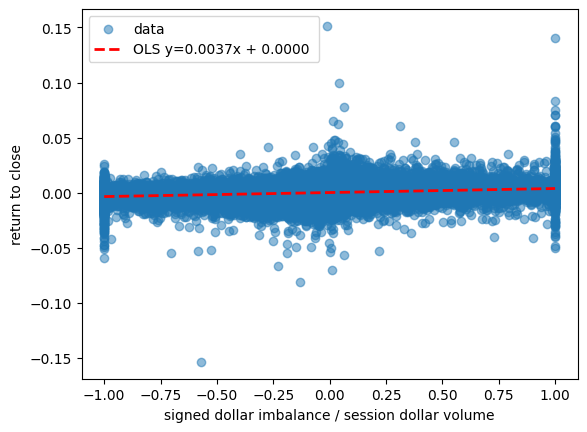

In [6]:
xs = np.linspace(np.min(X[:, 1]), np.max(X[:, 1])).clip()
plt.scatter(X[:, 1], y, alpha=0.5, label="data")
plt.plot(xs, res.params[1] * xs + res.params[0], label=f'OLS y={res.params[1]:,.4f}x + {res.params[0]:,.4f} ', color='red', linestyle='--', linewidth=2)
plt.xlabel("signed dollar imbalance / session dollar volume")
plt.ylabel("return to close")
plt.legend()
plt.show()

In [7]:
from scipy.stats import spearmanr

ic, pval = spearmanr(X[:, 1], y)
print(f"Spearman IC: {ic:,.3f} with p-value: {pval:,.3f}")

Spearman IC: 0.275 with p-value: 0.000


### Quick Backtest

In [8]:
CAP_PER_SYMBOL = 2_500
LEVERAGE = 2
COMMISSION = 0.0035
backtest = (
    data
    .with_columns(
        pl.when(pl.col("dollar_imbalance") > 500_000).then(True).otherwise(False).alias("tradable"),
    )
    .with_columns(
        ((pl.col("auction_price") - pl.col("last_traded_price")) / pl.col("last_traded_price")).alias("return"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            * pl.col("tradable") * (CAP_PER_SYMBOL // pl.col("last_traded_price"))
        ).alias("traded_qty"),
    )
    .with_columns(
        (pl.col("tradable") * pl.col("traded_qty") * pl.col("last_traded_price") * pl.col("return")).alias("gross_pnl"),
        (pl.col("tradable") * pl.col("traded_qty").abs() * (COMMISSION + pl.col("last_traded_spread")/2)).alias("cost"),
        (pl.col("traded_qty") * pl.col("last_traded_price")).alias("trade_value")
    )
    .with_columns(
        (pl.col("gross_pnl") - pl.col("cost")).alias("net_pnl")
    )

)
backtest.filter(pl.col("tradable") == True)

date,symbol,side,last_traded_price,last_traded_spread,auction_price,auction_dollars,dollar_imbalance,qty_signal,tradable,return,traded_qty,gross_pnl,cost,trade_value,net_pnl
date,cat,str,f64,f64,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64
2025-06-02,"""AAL""","""B""",11.335,0.01,11.38,1.6292e7,6.2903e6,0.148609,true,0.00397,220.0,9.9,1.87,2493.7,8.03
2025-06-02,"""AAON""","""A""",93.74,0.05,94.07,4.7473e6,734452.9,-0.086858,true,0.00352,-26.0,-8.58,0.741,-2437.24,-9.321
2025-06-02,"""AAPL""","""A""",201.59,0.01,201.7,8.84789322e8,1.6576e8,-0.110046,true,0.000546,-12.0,-1.32,0.102,-2419.08,-1.422
2025-06-02,"""ABNB""","""A""",129.3,0.03,129.62,7.2581e7,6636839.7,-0.057894,true,0.002475,-19.0,-6.08,0.3515,-2456.7,-6.4315
2025-06-02,"""ACAD""","""A""",21.395,0.01,21.465,4.8028e6,852034.48,-0.163909,true,0.003272,-116.0,-8.12,0.986,-2481.82,-9.106
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-01,"""XRAY""","""B""",9.975,0.01,10.02,5.3326e6,801640.875,0.08897,true,0.004511,250.0,11.25,2.125,2493.75,9.125
2026-06-01,"""Z""","""A""",36.39,0.01,36.25,2.4858e7,1.9008e6,-0.048732,true,-0.003847,-68.0,9.52,0.578,-2474.52,8.942
2026-06-01,"""ZBRA""","""B""",250.94,0.54,249.96,3.6508e7,2.3932e6,0.05965,true,-0.003905,9.0,-8.82,2.4615,2258.46,-11.2815


In [ ]:
N_days = backtest["date"].n_unique()
stat_backtest = backtest.filter(pl.col("tradable") == True, pl.col("traded_qty") != 0)
total_capital = stat_backtest.group_by("date").agg(pl.col("trade_value").abs().sum()).max()['trade_value'].item()

daily_returns = stat_backtest.group_by("date").agg(pl.col("net_pnl").sum() / pl.col("trade_value").abs().sum()).rename({"net_pnl":"return"})
cum_return = daily_returns.select((1+pl.col('return')).cum_prod()).tail(1).item()-1
daily_avg_return = daily_returns["return"].mean()
daily_std_return = daily_returns["return"].std()

n_trades = len(stat_backtest)
n_days = backtest['date'].n_unique()
n_profitable_trades = len(stat_backtest.filter(pl.col("net_pnl") > 0))

print(f"Total Invested Capital: ${total_capital:,.2f}")
print(f"Total Gross PNL: ${stat_backtest["gross_pnl"].sum():,.2f}")
print(f"Total Trading Costs PNL: ${stat_backtest["cost"].sum():,.2f}")
print(f"Total Net PNL: ${stat_backtest["net_pnl"].sum():,.2f}")
print(f"Total Return: {cum_return:,.4%}")
print(f"Annualized Return: {(1 + daily_avg_return)**252 - 1:,.2%}")
print(f"Sharpe (Annualized): {daily_avg_return / daily_std_return * 252**0.5:,.2f}")
print()
print(f"Per Trade Average Return (bps): {(stat_backtest['net_pnl'] / stat_backtest['trade_value'].abs()).mean() * 1e4:,.2f}")
print(f"Per Trade Hit Rate: {n_profitable_trades / n_trades:,.2%}")

Total Invested Capital: $2,386,448.71
Total Gross PNL: $367,823.76
Total Trading Costs PNL: $175,392.14
Total Net PNL: $192,431.62
Total Return: 14.7824%
Annualized Return: 15.04%
Sharpe (Annualized): 16.02

Per Trade Average Return (bps): 6.02
Per Trade Hit Rate: 54.83%


In [ ]:
LEVERAGE = 2.0
ANNUAL_FINANCING_RATE = 0.045          # broker rate on the borrowed (L-1)×equity
daily_financing = (LEVERAGE - 1) * ANNUAL_FINANCING_RATE / 252

levered = (
    daily_returns
    .sort("date")
    .with_columns((pl.col("return") * LEVERAGE - daily_financing).alias("lev_return"))
    .with_columns(((1 + pl.col("lev_return")).cum_prod() - 1).alias("cum_lev_return"))
)

lev_avg = levered["lev_return"].mean()
lev_std = levered["lev_return"].std()
print(f"Levered ({LEVERAGE:.1f}x) Total Return: {levered['cum_lev_return'].tail(1).item():,.2%}")
print(f"Levered Annualized:    {(1 + lev_avg)**252 - 1:,.2%}")
print(f"Levered Sharpe:        {lev_avg / lev_std * 252**0.5:,.2f}")

Levered (4.0x) Total Return: 51.89%
Levered Annualized:    53.01%
Levered Sharpe:        12.16


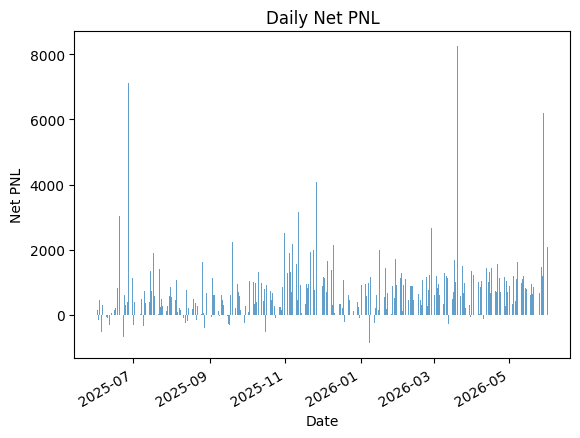

In [46]:
daily_pnl = stat_backtest.group_by("date").agg(pl.col("net_pnl").sum())
plt.bar(daily_pnl['date'], daily_pnl['net_pnl'],
        color='tab:blue', alpha=0.7)
plt.title("Daily Net PNL")
plt.xlabel("Date")
plt.ylabel("Net PNL")
plt.gcf().autofmt_xdate()
plt.show()

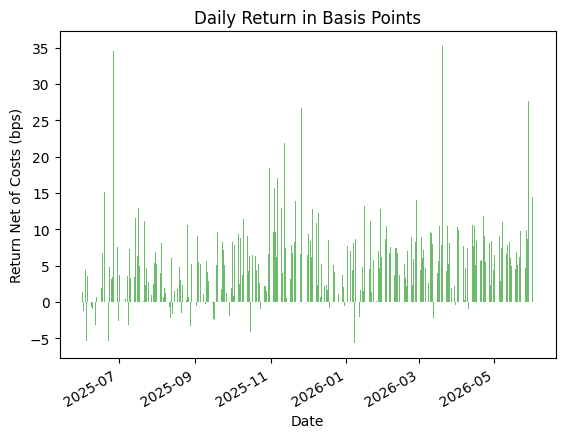

In [47]:
daily_return = stat_backtest.group_by("date").agg(pl.col("net_pnl").sum() / pl.col("trade_value").abs().sum(),
                                                  pl.col("symbol").n_unique()
                                                  ).rename({"net_pnl":"return"})
plt.bar(daily_return['date'], daily_return['return'] * 1e4,
        color='tab:green', alpha=0.7)
plt.title("Daily Return in Basis Points")
plt.xlabel("Date")
plt.ylabel("Return Net of Costs (bps)")
plt.gcf().autofmt_xdate()
plt.show()

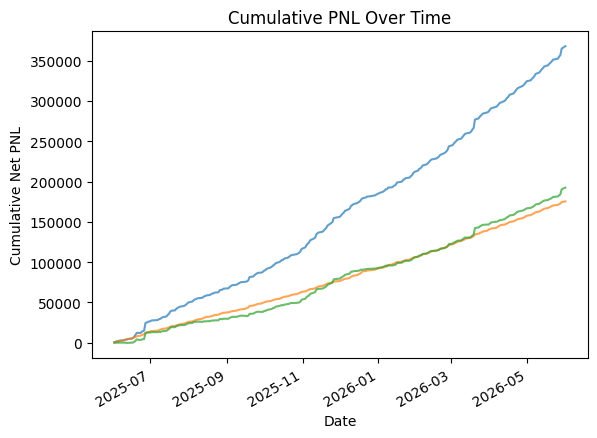

In [48]:
daily_pnl = stat_backtest.group_by("date").agg(pl.col(["gross_pnl", "cost", "net_pnl"]).sum())
plt.plot(daily_pnl['date'], daily_pnl['gross_pnl'].cum_sum(),
        color='tab:blue', alpha=0.7, label="gross_pnl")
plt.plot(daily_pnl['date'], daily_pnl['cost'].cum_sum(),
        color='tab:orange', alpha=0.7, label="cost")
plt.plot(daily_pnl['date'], daily_pnl['net_pnl'].cum_sum(),
        color='tab:green', alpha=0.7, label="net_pnl")
plt.title("Cumulative PNL Over Time")
plt.xlabel("Date")
plt.ylabel("Cumulative Net PNL")
plt.gcf().autofmt_xdate()
plt.show()

[GenericAdapter] scan_parquet: 2dc26d9b9bd336b41669afd2da204d21.parquet


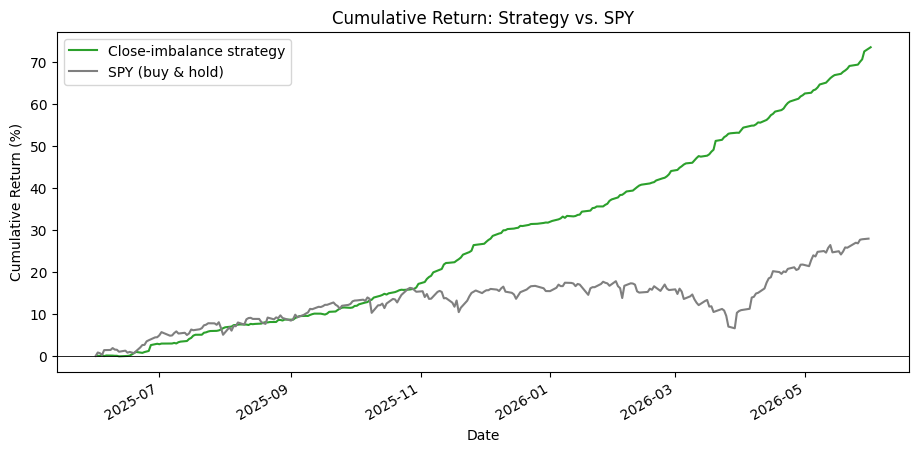

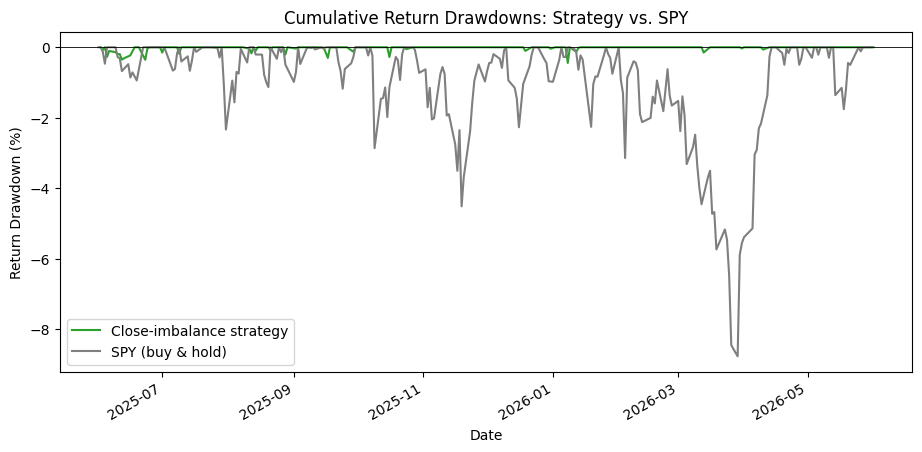

In [49]:
# --- Strategy cumulative return curve (compounded daily) ---
strat = (
    stat_backtest
    .group_by("date")
    .agg((LEVERAGE * pl.col("net_pnl").sum() / pl.col("trade_value").abs().sum()).alias("return"),
         pl.col("net_pnl").sum())
    .sort("date")
    .with_columns(((1 + pl.col("return")).cum_prod() - 1).alias("cum_return"),
                  pl.col("net_pnl").cum_sum().alias("cum_pnl"))
)

spy = adapter.scan_data(
    tickers=["SPY"],
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="ohlcv-1d",
)
spy = (
    spy
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York").dt.date().alias("date"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .sort("ts_event")
    .with_columns(pl.col("close").pct_change().fill_null(0.0).alias("return"))
    .with_columns(((1+pl.col("return")).cum_prod() - 1).alias("cum_return"))
    .select(["date", "close", "return", "cum_return"])
    .collect(engine="streaming")
)

# --- Plot ---
plt.figure(figsize=(11, 5))
plt.plot(strat["date"], strat["cum_return"] * 100, label="Close-imbalance strategy", color="tab:green")
plt.plot(spy["date"], spy["cum_return"] * 100, label="SPY (buy & hold)", color="tab:gray")
plt.axhline(0, color="black", lw=0.6)
plt.title("Cumulative Return: Strategy vs. SPY")
plt.xlabel("Date")
plt.ylabel("Cumulative Return (%)")
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(strat["date"], (strat["cum_pnl"]- strat["cum_pnl"].cum_max()) / strat["cum_pnl"].max() * 100, label="Close-imbalance strategy", color="tab:green")
plt.plot(spy["date"], (spy["close"] - spy["close"].cum_max()) / spy["close"].max() * 100, label="SPY (buy & hold)", color="tab:gray")
plt.axhline(0, color="black", lw=0.6)
plt.title("Cumulative Return Drawdowns: Strategy vs. SPY")
plt.xlabel("Date")
plt.ylabel("Return Drawdown (%)")
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

In [50]:
print(f"Minimum Capital: {backtest.filter(pl.col("tradable")==True).group_by("date").agg(pl.col("last_traded_price").sum())['last_traded_price'].max():,.2f}")
print(f"N Symbols: {backtest.filter(pl.col("tradable")==True)['symbol'].n_unique()}")

Minimum Capital: 102,670.49
N Symbols: 1319


### Next Step: Look at what's happening on the down-days

### Looking at data costs

In [15]:
# import databento as db
# import pandas as pd
# START = pd.Timestamp(2025,6,2,15,45,00, tz="US/Eastern")
# END = pd.Timestamp(2025,6,2,16,00,00, tz="US/Eastern")
# DATASET = "XNAS.ITCH"
# # SCHEMAS = ["imbalance", "bbo-1m", "ohlcv-1m", "statistics"]
# SCHEMAS = ["imbalance", "tbbo", "statistics"]


# client = db.Historical(os.getenv("DATABENTO-API-KEY"))
# total_cost = 0
# total_size = 0
# for schema in SCHEMAS:
#     cost = client.metadata.get_cost(
#         dataset=DATASET,
#         symbols=UNIVERSE,
#         start=START,
#         end=END,
#         schema=schema
#     )

#     size = client.metadata.get_billable_size(
#         dataset=DATASET,
#         symbols=UNIVERSE,
#         start=START,
#         end=END,
#         schema=schema
#     )
#     print(f"{schema} Cost: ${cost:,.2f}, Uncompressed Size: {size / 1e9:,.2f} GB")
#     total_cost += cost
#     total_size += size

# print(f"Total Cost: ${total_cost:,.2f}, Uncompressed Size: {total_size / 1e9:,.2f} GB")